# Train on PanopTILs Refined

Train a CellPose network on real breast tissue images and labelled nuclei from
[PanopTILs Refined](https://huggingface.co/datasets/histolytics-hub/panoptils_refined).
An instance label identifies one nucleus; a class label describes its cell type.
We use the `image`, `inst` and `type` fields only, never the tissue-area `sem` masks.

This short example uses three training regions and one validation region from
separate patients. It runs three epochs (passes through the training data), then
shows a held-out image, its instance labels and predicted cell classes. This small
subset teaches the workflow; a useful model needs more patients and training.

The dataset is CC0-1.0 and builds on PanopTILs, BCSS and NuCLS. See its dataset
card for attribution and annotation details.

## Prepare the data

From the repository root, install the notebook dependencies and download the
small example subset:

```sh
uv sync --locked --group docs
uv run --locked --group docs python tools/prepare_panoptils.py data/panoptils
```

The preparation step checks the sample bytes and creates aligned 256 × 256 crops.
It downloads only four regions, not the full archive, and refuses to overwrite an
existing destination. Open the notebook in `docs/tutorials/` with a kernel from this environment.
The data path below is relative to that notebook directory; change it if your
data is elsewhere.

Each split has an `images/` folder of PNG images and a `labels/` folder of matching
MAT files containing `inst` and `type`. Matching files have the same name.
The preparation step separates patients before cropping. Keep that separation
when extending the example to more regions or patients.

## Setup

In [1]:
from pathlib import Path

import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from skimage.color import label2rgb
from torch.utils.data import DataLoader

from cellseg_models_pytorch.models.cellpose.cellpose_unet import cellpose_nuclei
from cellseg_models_pytorch.torch_datasets import TrainDatasetFolder
from cellseg_models_pytorch.transforms.albu_transforms import (
    ApplyEach,
    CellposeTransform,
    MinMaxNormalization,
)

# Fix the seed; GPU operations can still introduce small run-to-run differences.
torch.manual_seed(0)
torch.set_num_threads(2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_root = Path("../../data/panoptils")
print(f"Device: {device}")

Device: cuda


## Load images and targets

The folder dataset loads images together with their labels. `CellposeTransform`
creates flows that point toward each nucleus's centre; these are the second target
the model learns, alongside cell classes. We crop during preparation, before
computing these flows. This example normalizes each image to [0, 1] without any
geometric augmentation.

Images become channel-first float32 tensors. Class labels are integer grids;
flow targets have two channels, vertical and horizontal. We choose their training
dtypes explicitly in the loop.

In [2]:
transforms = A.Compose([MinMaxNormalization(copy=True)])
instance_transforms = ApplyEach([CellposeTransform()], as_list=True)

train_dataset = TrainDatasetFolder(
    str(data_root / "train/images"),
    str(data_root / "train/labels"),
    mask_keys=("inst", "type"),
    transforms=transforms,
    inst_transforms=instance_transforms,
)
validation_dataset = TrainDatasetFolder(
    str(data_root / "validation/images"),
    str(data_root / "validation/labels"),
    mask_keys=("inst", "type"),
    transforms=transforms,
    inst_transforms=instance_transforms,
)

# Shuffle training examples; keep validation order fixed.
train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True, num_workers=0)
validation_loader = DataLoader(
    validation_dataset, batch_size=2, shuffle=False, num_workers=0
)
print(f"Regions: {len(train_dataset)} training, {len(validation_dataset)} validation")

Regions: 3 training, 1 validation


## Create the network

Keep the dataset's seven class IDs: 0 background, 1 neoplastic, 2 stromal,
3 inflammatory, 4 epithelial, 5 other and 6 unknown. The small subset does not
cover every class; do not renumber the labels.

We start a small ResNet-18 encoder from random weights, with no checkpoint download.
The network predicts class logits (scores) and flows. Cross entropy trains the
class scores; mean squared error trains the flows.

In [3]:
model = cellpose_nuclei(7, enc_name="resnet18", enc_pretrain=False).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
num_epochs = 3

## Train and validate

Training updates the weights. Validation uses held-out patients without changing
weights or tracking gradients. The reported losses average both target losses
over all images in each split. Lower loss alone does not establish segmentation
quality; a full evaluation also needs reconstructed instances and instance metrics.

In [4]:
for epoch in range(num_epochs):
    model.train()
    training_total = 0.0

    for batch in train_loader:
        images = batch["image"].to(device)
        class_targets = batch["type"].long().to(device)
        flow_targets = batch["cellpose_inst"].float().to(device)

        optimizer.zero_grad(set_to_none=True)
        prediction = model(images)["nuc"]
        classification_loss = F.cross_entropy(prediction.type_map, class_targets)
        flow_loss = F.mse_loss(prediction.aux_map, flow_targets)
        loss = classification_loss + flow_loss

        # Compute gradients, then update the network weights.
        loss.backward()
        optimizer.step()
        training_total += float(loss.detach()) * images.shape[0]

    model.eval()
    validation_total = 0.0

    with torch.inference_mode():
        for batch in validation_loader:
            images = batch["image"].to(device)
            class_targets = batch["type"].long().to(device)
            flow_targets = batch["cellpose_inst"].float().to(device)

            output = model(images)["nuc"]
            classification_loss = F.cross_entropy(output.type_map, class_targets)
            flow_loss = F.mse_loss(output.aux_map, flow_targets)
            validation_total += float(classification_loss + flow_loss) * images.shape[0]

    training_loss = training_total / len(train_dataset)
    validation_loss = validation_total / len(validation_dataset)
    print(
        f"Epoch {epoch + 1}: training loss {training_loss:.3f}, "
        f"validation loss {validation_loss:.3f}"
    )

Epoch 1: training loss 6.929, validation loss 2.255


Epoch 2: training loss 5.014, validation loss 2.149


Epoch 3: training loss 4.322, validation loss 2.269


## View a held-out prediction

Compare the tissue image and labelled nuclei with the model's predicted classes.
These class predictions are dense pixel labels, not reconstructed instances.
Colours display label numbers; the short training run is not a quality benchmark.

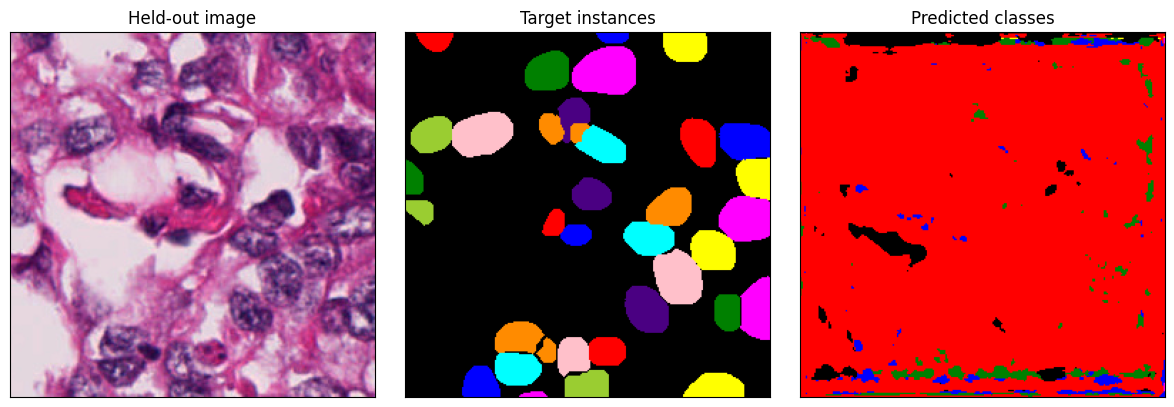

In [5]:
example = validation_dataset[0]
model.eval()
with torch.inference_mode():
    output = model(example["image"].unsqueeze(0).to(device))["nuc"]

# Move only the displayed maps to CPU for plotting.
# Keep display pixels in the RGB range after floating-point normalization.
image = example["image"].permute(1, 2, 0).numpy().clip(0, 1)
instances = example["inst"].long().numpy()
predicted_classes = output.type_map.argmax(dim=1)[0].cpu().numpy()
instance_colors = label2rgb(instances, bg_label=0)
class_colors = label2rgb(predicted_classes, bg_label=0)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image)
axes[0].set(title="Held-out image", xticks=[], yticks=[])

axes[1].imshow(instance_colors)
axes[1].set(title="Target instances", xticks=[], yticks=[])

axes[2].imshow(class_colors)
axes[2].set(title="Predicted classes", xticks=[], yticks=[])

fig.tight_layout()
plt.show()

For a longer run, use more patients, choose losses and instance metrics for your
application, and save resumable checkpoints as shown in the
[fine-tuning example](finetuning.ipynb). `TrainDatasetH5` is an alternative for
larger prepared datasets and requires PyTables.